Alegem un graf ca fiind un simplu path, P5 in cazul de fata

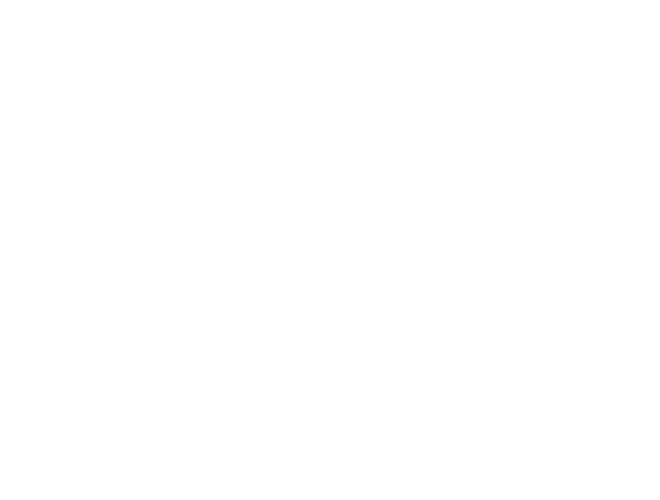

S1 : ['S2']
S2 : ['S1', 'S3']
S3 : ['S2', 'S4']
S4 : ['S3', 'S5']
S5 : ['S4']
Contine cicluri: False


In [3]:
from pgmpy.models import DiscreteMarkovNetwork
import networkx as nx
import matplotlib.pyplot as plt

edges = [
    ("S1", "S2"),
    ("S2", "S3"),
    ("S3", "S4"),
    ("S4", "S5")
]

model = DiscreteMarkovNetwork()
model.add_edges_from(edges)

nx.draw(
    model,
    with_labels=True,
    node_size=2000
)

plt.show()

for statie in model.nodes():
    print(statie, ":", list(model.neighbors(statie)))

print("Contine cicluri:", len(nx.cycle_basis(model)) > 0)

Codificam starile: 0 soare, 1 ploaie, 2 nori. Pentru fiecare avem 0.5,0.3,0.2

In [4]:
from pgmpy.factors.discrete import DiscreteFactor
import numpy as np

pi = np.array([0.5, 0.3, 0.2])

Psi = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6]
])

for statie in ["S1", "S2", "S3", "S4", "S5"]:
    factor = DiscreteFactor(
        variables=[statie],
        cardinality=[3],
        values=pi
    )

    model.add_factors(factor)

for s1, s2 in edges:
    factor = DiscreteFactor(
        variables=[s1, s2],
        cardinality=[3, 3],
        values=Psi.flatten()
    )

    model.add_factors(factor)

C. Pentru modelul ales, distributia comuna se scrie ca produsul factorilor unari si al factorilor pereche, normalizat prin constanta \(Z\):

P(s_1,s_2,s_3,s_4,s_5)
=
$\frac{1}{Z}
\left(\prod_{i=1}^{5}\phi_i(s_i)\right)
\left(\prod_{(i,j)\in E}\phi_{ij}(s_i,s_j)\right)$

In cazul lantului \(S_1-S_2-S_3-S_4-S_5\), aceasta devine:

P(s_1,s_2,s_3,s_4,s_5)
=
$\frac{1}{Z}
\phi_1(s_1)\phi_2(s_2)\phi_3(s_3)\phi_4(s_4)\phi_5(s_5)
\Psi(s_1,s_2)\Psi(s_2,s_3)\Psi(s_3,s_4)\Psi(s_4,s_5)$

Constanta \(Z\) are rolul de a normaliza distributia astfel incat suma probabilitatilor tuturor configuratiilor sa fie egala cu 1.

Pentru d, alegem doua statii s1 = soare, s5 =ploaie, vrem distributia lui S3, asa cum avem 3^5 configuratii, le putem enumera

In [5]:
from itertools import product

statii = ["S1", "S2", "S3", "S4", "S5"]

stari = {
    0: "Soare",
    1: "Ploaie",
    2: "Nori"
}

observatii = {
    "S1": 0,   #soare
    "S5": 1    #ploaie
}

def pondere(config):
    p = 1

    for statie in statii:
        p *= pi[config[statie]]

    for s1, s2 in edges:
        p *= Psi[config[s1], config[s2]]

    return p


configuratii = []

for valori in product([0, 1, 2], repeat=5):
    config = dict(zip(statii, valori))

    valid = True

    for statie, valoare in observatii.items():
        if config[statie] != valoare:
            valid = False

    if valid:
        configuratii.append(config)

Calculam acum probabilitatile pentru S3

In [6]:
total = sum(pondere(c) for c in configuratii)

prob_S3 = []

for stare in [0, 1, 2]:
    suma = 0

    for config in configuratii:
        if config["S3"] == stare:
            suma += pondere(config)

    prob_S3.append(suma / total)

for i in range(3):
    print(stari[i], prob_S3[i])

Soare 0.711398862075731
Ploaie 0.2307239552678046
Nori 0.0578771826564646


pentru e, dorim toate configurarile pentru toate statiile necunoscute, s2,s3,s4

In [7]:
config_MAP = max(
    configuratii,
    key=pondere
)

print("Configuratia MAP:")

for statie in statii:
    print(statie, "=", stari[config_MAP[statie]])

Configuratia MAP:
S1 = Soare
S2 = Soare
S3 = Soare
S4 = Soare
S5 = Ploaie


In [8]:
for statie in ["S2", "S3", "S4"]:

    probabilitati = []

    for stare in [0, 1, 2]:
        suma = 0

        for config in configuratii:
            if config[statie] == stare:
                suma += pondere(config)

        probabilitati.append(suma / total)

    stare_max = np.argmax(probabilitati)

    print(
        statie,
        stari[stare_max],
        probabilitati
    )

S2 Soare [np.float64(0.8514812634883268), np.float64(0.11889346674514421), np.float64(0.029625269766529336)]
S3 Soare [np.float64(0.711398862075731), np.float64(0.2307239552678046), np.float64(0.0578771826564646)]
S4 Soare [np.float64(0.48337257210123613), np.float64(0.43790464979399646), np.float64(0.07872277810476752)]
